# Partie 4 – Analyse RFM et segmentation des clients

Objectif : analyser le comportement des clients de ClassicModels avec la méthode RFM (Recency, Frequency, Monetary)
et les segmenter en catégories métier : VIP, Réguliers, À risque, Perdus.

- **Recency (R)** : nombre de jours depuis la dernière commande.
- **Frequency (F)** : nombre de commandes passées.
- **Monetary (M)** : montant total dépensé.

Nous utiliserons MySQL comme source de données et Python (pandas, seaborn, matplotlib) pour le calcul et la visualisation.

In [1]:
import sys
from pathlib import Path

# Met le dossier racine du projet dans le PYTHONPATH
PROJECT_ROOT = Path().resolve().parent  # parent de notebooks/ = racine du projet
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import fetch_dataframe

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.database.connection import fetch_dataframe  # utilise ton module existant

sns.set_style("whitegrid")

## Extraction des données depuis MySQL

On récupère toutes les commandes livrées (status = 'Shipped') avec le montant de chaque commande.

In [3]:
query_orders = """
SELECT
    c.customerNumber,
    c.customerName,
    o.orderNumber,
    o.orderDate,
    SUM(od.quantityOrdered * od.priceEach) AS order_amount
FROM customers c
JOIN orders o ON o.customerNumber = c.customerNumber
JOIN orderdetails od ON od.orderNumber = o.orderNumber
WHERE o.status = 'Shipped'
GROUP BY
    c.customerNumber,
    c.customerName,
    o.orderNumber,
    o.orderDate
ORDER BY
    c.customerNumber,
    o.orderDate;
"""

df_orders = fetch_dataframe(query_orders)
df_orders["orderDate"] = pd.to_datetime(df_orders["orderDate"])
print(f"Nombre de commandes récupérées : {len(df_orders)}")
df_orders.head()

Nombre de commandes récupérées : 303


C:\Users\bourbia\Desktop\python sql project\src\database\connection.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


,customerNumber,customerName,orderNumber,orderDate,order_amount
0,103,Atelier graphique,10123,2003-05-20,14571.44
1,103,Atelier graphique,10298,2004-09-27,6066.78
2,103,Atelier graphique,10345,2004-11-25,1676.14
3,112,Signal Gift Stores,10124,2003-05-21,32641.98
4,112,Signal Gift Stores,10278,2004-08-06,33347.88


In [4]:
# Date de référence : on prend la date la plus récente dans les commandes
reference_date = df_orders["orderDate"].max()

# Calcul des métriques RFM par client
rfm = df_orders.groupby(["customerNumber", "customerName"]).agg({
    "orderDate": lambda x: (reference_date - x.max()).days,  # Recency : jours depuis dernière commande
    "orderNumber": "count",  # Frequency : nombre de commandes
    "order_amount": "sum"  # Monetary : montant total dépensé
}).reset_index()

# Renommer les colonnes
rfm.columns = ["customerNumber", "customerName", "recency", "frequency", "monetary"]

print(f"Nombre de clients analysés : {len(rfm)}")
print(f"\nStatistiques RFM :")
print(rfm[["recency", "frequency", "monetary"]].describe())
rfm.head()

Nombre de clients analysés : 98

Statistiques RFM :
          recency  frequency       monetary
count   98.000000  98.000000      98.000000
mean   194.581633   3.091837   90460.149388
std    136.876943   2.483292   85524.861536
min      0.000000   1.000000    7918.600000
25%     86.500000   2.000000   55848.540000
50%    181.000000   3.000000   76357.100000
75%    249.000000   3.000000  103390.685000
max    546.000000  22.000000  668770.460000


,customerNumber,customerName,recency,frequency,monetary
0,103,Atelier graphique,173,3,22314.36
1,112,Signal Gift Stores,169,3,80180.98
2,114,"Australian Collectors, Co.",169,5,180585.07
3,119,La Rochelle Gifts,103,3,116949.68
4,121,Baane Mini Imports,193,4,104224.79


## Interprétation des statistiques RFM

**Analyse globale des 98 clients :**

- **Recency moyenne : 195 jours** : Près de 6,5 mois depuis la dernière commande en moyenne. Cela indique un besoin d'actions de relance pour réactiver les clients inactifs.

- **Frequency moyenne : 3,1 commandes** : Les clients commandent en moyenne 3 fois, ce qui montre une fidélité modérée. Il y a une opportunité d'augmenter la fréquence d'achat.

- **Monetary moyen : $90,460** : Le panier moyen par client sur l'ensemble de leur historique est élevé, indiquant une bonne valeur client.

- **Écart-type élevé** (notamment pour Monetary : $85,525) : Grande hétérogénéité entre les clients. Les meilleurs clients dépensent beaucoup plus que la moyenne, confirmant l'importance de la segmentation.

**Points d'attention :**
- 25% des clients n'ont pas commandé depuis plus de 249 jours (8+ mois) : risque de perte de clients
- Le client le plus actif a passé 22 commandes, montrant un potentiel de croissance pour les autres

## Attribution des scores R, F, M (1 à 4)

On divise les clients en 4 groupes (quartiles) pour chaque métrique :
- **Score 4** = meilleur quartile (top 25%)
- **Score 3** = deuxième quartile
- **Score 2** = troisième quartile
- **Score 1** = dernier quartile (bottom 25%)

**Logique inverse pour Recency** : plus c'est récent (petit nombre de jours), meilleur c'est → score 4.
**Logique normale pour Frequency et Monetary** : plus c'est élevé, meilleur c'est → score 4.

In [5]:
# Calcul des seuils (quartiles) pour chaque métrique
r_quartiles = rfm["recency"].quantile([0.25, 0.5, 0.75]).to_dict()
f_quartiles = rfm["frequency"].quantile([0.25, 0.5, 0.75]).to_dict()
m_quartiles = rfm["monetary"].quantile([0.25, 0.5, 0.75]).to_dict()

def r_score(x):
    # Recency : plus c'est récent (petit nombre), meilleur c'est → score 4
    if x <= r_quartiles[0.25]:
        return 4  # Top 25% : clients très récents
    elif x <= r_quartiles[0.5]:
        return 3
    elif x <= r_quartiles[0.75]:
        return 2
    else:
        return 1  # Bottom 25% : clients qui n'ont pas commandé depuis longtemps

def fm_score(x, quartiles):
    # Frequency et Monetary : plus c'est élevé, meilleur c'est → score 4
    if x <= quartiles[0.25]:
        return 1  # Bottom 25%
    elif x <= quartiles[0.5]:
        return 2
    elif x <= quartiles[0.75]:
        return 3
    else:
        return 4  # Top 25%

# Application des scores
rfm["R"] = rfm["recency"].apply(r_score)
rfm["F"] = rfm["frequency"].apply(fm_score, quartiles=f_quartiles)
rfm["M"] = rfm["monetary"].apply(fm_score, quartiles=m_quartiles)

# Score RFM combiné (ex: "443" = R=4, F=4, M=3)
rfm["RFM_Score"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

print("Exemples de scores RFM :")
rfm[["customerName", "recency", "frequency", "monetary", "R", "F", "M", "RFM_Score"]].head(10)

Exemples de scores RFM :


,customerName,recency,frequency,monetary,R,F,M,RFM_Score
0,Atelier graphique,173,3,22314.36,3,2,1,321
1,Signal Gift Stores,169,3,80180.98,3,2,3,323
2,"Australian Collectors, Co.",169,5,180585.07,3,4,4,344
3,La Rochelle Gifts,103,3,116949.68,3,2,4,324
4,Baane Mini Imports,193,4,104224.79,2,4,4,244
5,Mini Gifts Distributors Ltd.,55,16,584188.24,4,4,4,444
6,"Blauer See Auto, Co.",193,4,75937.76,2,4,2,242
7,Mini Wheels Co.,180,3,66710.56,3,2,2,322
8,Land of Toys Inc.,183,3,107639.94,2,2,4,224
9,Euro+ Shopping Channel,14,22,668770.46,4,4,4,444


## Segmentation des clients en 4 catégories

Basée sur les scores R, F, M :
- **VIP** : R≥3 et F≥3 et M≥3 → clients récents, fréquents, qui dépensent beaucoup
- **Régulier** : R≥2 et F≥2 et M≥2 → clients fidèles mais moins actifs que les VIP
- **À risque** : R≥2 mais (F=1 ou M=1) → clients récents mais qui achètent peu/fréquemment
- **Perdu** : tous les autres → clients qui n'ont pas commandé depuis longtemps ou très peu actifs

In [6]:
def segment_client(row):
    r, f, m = row["R"], row["F"], row["M"]
    
    # VIP : récent (R≥3) + fréquent (F≥3) + gros dépensier (M≥3)
    if r >= 3 and f >= 3 and m >= 3:
        return "VIP"
    # Régulier : assez récent (R≥2) + assez fréquent (F≥2) + dépense moyenne (M≥2)
    elif r >= 2 and f >= 2 and m >= 2:
        return "Régulier"
    # À risque : récent (R≥2) mais achète peu (F=1) ou dépense peu (M=1)
    elif r >= 2 and (f == 1 or m == 1):
        return "À risque"
    # Perdu : tous les autres (anciens clients ou très peu actifs)
    else:
        return "Perdu"

rfm["segment"] = rfm.apply(segment_client, axis=1)

print("Répartition par segment :")
print(rfm["segment"].value_counts())
print("\nExemples de clients par segment :")
rfm[["customerName", "recency", "frequency", "monetary", "R", "F", "M", "segment"]].head(15)

Répartition par segment :
segment
Régulier    36
À risque    25
Perdu       24
VIP         13
Name: count, dtype: int64

Exemples de clients par segment :


,customerName,recency,frequency,monetary,R,F,M,segment
0,Atelier graphique,173,3,22314.36,3,2,1,À risque
1,Signal Gift Stores,169,3,80180.98,3,2,3,Régulier
2,"Australian Collectors, Co.",169,5,180585.07,3,4,4,VIP
3,La Rochelle Gifts,103,3,116949.68,3,2,4,Régulier
4,Baane Mini Imports,193,4,104224.79,2,4,4,Régulier
5,Mini Gifts Distributors Ltd.,55,16,584188.24,4,4,4,VIP
6,"Blauer See Auto, Co.",193,4,75937.76,2,4,2,Régulier
7,Mini Wheels Co.,180,3,66710.56,3,2,2,Régulier
8,Land of Toys Inc.,183,3,107639.94,2,2,4,Régulier
9,Euro+ Shopping Channel,14,22,668770.46,4,4,4,VIP


## Interprétation de la répartition par segment

**Distribution des clients :**
- **Régulier (36 clients, 37%)** : Segment majoritaire, base solide de l'entreprise
- **À risque (25 clients, 26%)** : Segment préoccupant nécessitant une action rapide
- **Perdu (24 clients, 24%)** : Près d'1 client sur 4 est perdu, impact significatif sur les revenus
- **VIP (13 clients, 13%)** : Segment premium à choyer absolument

**Implications stratégiques :**
1. **Priorité 1 - Segment VIP (13%)** : Ces clients représentent probablement une part disproportionnée du CA. Actions recommandées :
   - Programme de fidélité premium
   - Service client dédié
   - Offres exclusives et avant-premières

2. **Priorité 2 - Segment À risque (26%)** : Clients récents mais peu actifs. Actions recommandées :
   - Campagnes de relance ciblées
   - Offres promotionnelles pour augmenter la fréquence
   - Enquête de satisfaction pour comprendre les freins

3. **Priorité 3 - Segment Perdu (24%)** : Clients inactifs depuis longtemps. Actions recommandées :
   - Campagne de réactivation avec offre attractive
   - Identifier les raisons de la perte (concurrence, insatisfaction, etc.)
   - Coût de réactivation vs acquisition de nouveaux clients

4. **Segment Régulier (37%)** : Maintenir la relation et tenter de les faire évoluer vers VIP

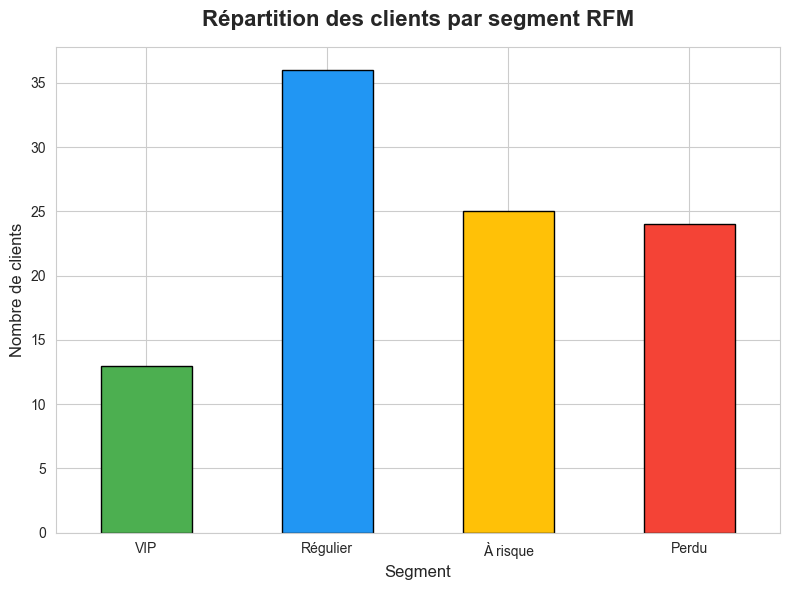

In [7]:
plt.figure(figsize=(8, 6))
segment_counts = rfm["segment"].value_counts().reindex(["VIP", "Régulier", "À risque", "Perdu"])
segment_counts.plot(kind="bar", color=["#4CAF50", "#2196F3", "#FFC107", "#F44336"], edgecolor="black")

plt.title("Répartition des clients par segment RFM", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Segment", fontsize=12)
plt.ylabel("Nombre de clients", fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

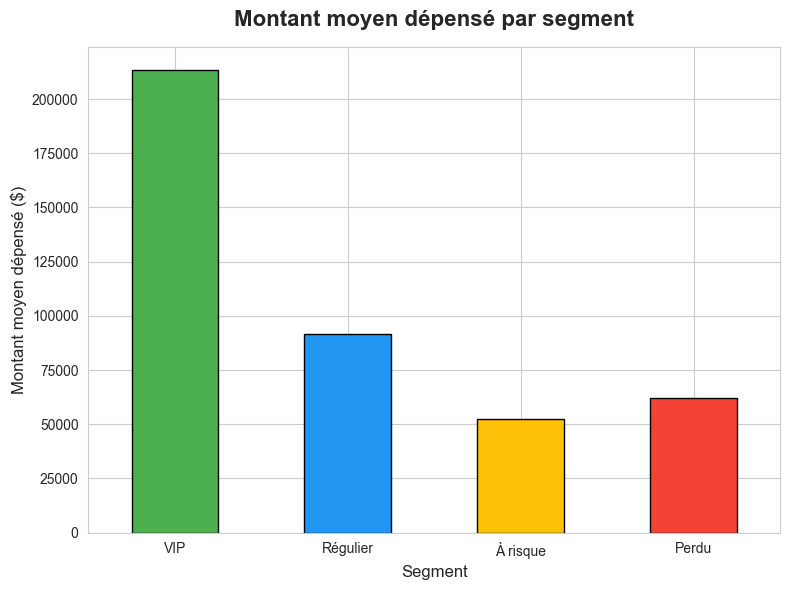

In [8]:
plt.figure(figsize=(8, 6))
segment_monetary = (
    rfm.groupby("segment")["monetary"]
    .mean()
    .reindex(["VIP", "Régulier", "À risque", "Perdu"])
)

segment_monetary.plot(kind="bar", color=["#4CAF50", "#2196F3", "#FFC107", "#F44336"], edgecolor="black")

plt.title("Montant moyen dépensé par segment", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Segment", fontsize=12)
plt.ylabel("Montant moyen dépensé ($)", fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Interprétation du montant moyen dépensé par segment

**Analyse de la valeur client par segment :**

- **VIP : $213,385** : Montant 2,3x supérieur à la moyenne, confirmant leur statut premium. Ces clients justifient un investissement marketing et service client élevé.

- **Régulier : $91,566** : Légèrement au-dessus de la moyenne globale, segment stable et rentable.

- **Perdu : $62,039** : Paradoxe intéressant : les clients perdus avaient un CA moyen supérieur aux "À risque". Cela suggère qu'ils étaient de bons clients avant de partir, d'où l'importance de la réactivation.

- **À risque : $52,230** : CA moyen le plus faible, confirmant leur faible valeur actuelle mais aussi leur potentiel de croissance s'ils sont bien accompagnés.

**Insight clé** : L'écart entre VIP ($213K) et les autres segments est très important. Cela confirme la stratégie de "80/20" : une minorité de clients génère une majorité du CA.

### Analyse par segment :

**1. Segment VIP (13 clients)**
- **CA moyen : $213,385** ; 2,3x supérieur au CA moyen global, confirmant leur valeur exceptionnelle
- **CA total : $2,77M** : Représente environ 31% du CA total estimé (sur 98 clients)
- **Fréquence : 6,6 commandes** : Clients très fidèles et actifs
- **Recency : 69 jours** : Dernière commande il y a environ 2 mois, excellente récence
- **Action** : Ces clients sont la pépite de l'entreprise. Il faut absolument les retenir et maximiser leur valeur.

**2. Segment Régulier (36 clients)**
- **CA moyen : $91,566** : Légèrement supérieur à la moyenne globale ($90,460)
- **CA total : $3,30M** : Segment le plus important en volume de CA
- **Fréquence : 3,1 commandes** : Fidélité moyenne, potentiel d'amélioration
- **Recency : 124 jours** : Dernière commande il y a environ 4 mois, acceptable mais perfectible
- **Action** : Segment à développer vers VIP grâce à des programmes d'incitation à la fréquence.

**3. Segment À risque (25 clients)**
- **CA moyen : $52,230** : 42% inférieur à la moyenne, valeur client faible
- **CA total : $1,31M** : Contribution limitée au CA global
- **Fréquence : 2,2 commandes** : Très faible fréquence d'achat
- **Recency : 172 jours** : Dernière commande il y a environ 6 mois, signe d'essoufflement
- **Action** : Segment critique nécessitant une intervention urgente. Campagnes de relance agressives pour éviter la perte définitive.

**4. Segment Perdu (24 clients)**
- **CA moyen : $62,039** : Paradoxalement supérieur au segment "À risque", mais clients inactifs depuis longtemps
- **CA total : $1,49M** : CA potentiellement récupérable
- **Fréquence : 2,1 commandes** : Très faible activité passée
- **Recency : 391 jours** : Dernière commande il y a plus d'un an, clients considérés comme perdus
- **Action** : Évaluer le coût de réactivation. Certains clients peuvent être récupérés avec une offre attractive, d'autres doivent être considérés comme perdus définitivement.


In [9]:
# Tableau récapitulatif des segments RFM
segment_analysis = rfm.groupby("segment").agg({
    "customerNumber": "count",
    "monetary": ["mean", "sum"],
    "frequency": "mean",
    "recency": "mean"
}).round(2)

segment_analysis.columns = ["Nombre_clients", "CA_moyen", "CA_total", "Frequence_moyenne", "Recency_moyenne"]
segment_analysis = segment_analysis.reindex(["VIP", "Régulier", "À risque", "Perdu"])

print("\nTableau récapitulatif des segments RFM :\n")
display(segment_analysis)


Tableau récapitulatif des segments RFM :



,Nombre_clients,CA_moyen,CA_total,Frequence_moyenne,Recency_moyenne
segment,,,,,
VIP,13,213385.37,2774009.79,6.62,69.31
Régulier,36,91566.36,3296388.85,3.06,124.31
À risque,25,52230.26,1305756.61,2.24,172.40
Perdu,24,62039.14,1488939.39,2.12,390.96


### Synthèse et recommandations globales :

1. **Concentration du CA** : Les VIP (13%) génèrent probablement 30%+ du CA total : stratégie de rétention premium essentielle
2. **Opportunité de croissance** : 49 clients (50%) sont "À risque" ou "Perdus" : potentiel de réactivation important
3. **Optimisation** : Focus sur l'augmentation de la fréquence d'achat des "Réguliers" pour les faire évoluer vers VIP
4. **ROI des actions** : Prioriser les investissements marketing sur les segments VIP et À risque (meilleur ROI attendu)